# Konvolusi dalam Domain Spasial

---

### 1. Konsep Dasar Konvolusi

Konvolusi dalam domain spasial adalah operasi matematika yang diterapkan pada citra digital menggunakan filter atau kernel. Tujuannya adalah memodifikasi tampilan citra, seperti memperhalus, menajamkan, atau mendeteksi tepi.

Secara matematis, konvolusi 2D diskret dirumuskan sebagai:

$$
g(x, y) = \sum_{i=-k}^{k} \sum_{j=-k}^{k} f(x+i, y+j) \cdot h(i, j)
$$

Dimana:
- $f(x, y)$: piksel citra masukan
- $h(i, j)$: nilai bobot kernel
- $g(x, y)$: nilai piksel citra luaran

### 2. Contoh Kernel dan Efeknya

| Nama Filter | Kernel | Efek |
| :--- | :--- | :--- |
| **Mean Filter** | $\frac{1}{9}\begin{bmatrix}1&1&1 \\ 1&1&1 \\ 1&1&1\end{bmatrix}$ | Menghaluskan (*blur*) |
| **Gaussian Filter** | $\frac{1}{16}\begin{bmatrix}1&2&1 \\ 2&4&2 \\ 1&2&1\end{bmatrix}$ | Menghaluskan secara natural |
| **Sharpen Filter** | $\begin{bmatrix}0&-1&0 \\ -1&5&-1 \\ 0&-1&0\end{bmatrix}$ | Menajamkan detail citra |
| **Edge Detection** | $\begin{bmatrix}-1&-1&-1 \\ -1&8&-1 \\ -1&-1&-1\end{bmatrix}$ | Deteksi tepi serbaguna |
| **Laplacian Filter** | $\begin{bmatrix}0&1&0 \\ 1&-4&1 \\ 0&1&0\end{bmatrix}$ | Deteksi tepi berbasis turunan kedua |
| **Sobel X Filter** | $\begin{bmatrix}-1&0&1 \\ -2&0&2 \\ -1&0&1\end{bmatrix}$ | Deteksi tepi vertikal |
| **Sobel Y Filter** | $\begin{bmatrix}-1&-2&-1 \\ 0&0&0 \\ 1&2&1\end{bmatrix}$ | Deteksi tepi horizontal |

### 3. Implementasi Python

#### a. Import Library & Load Citra
Jika `image.jpg` belum ada, kode berikut otomatis mengunduh sampel gambar uji.

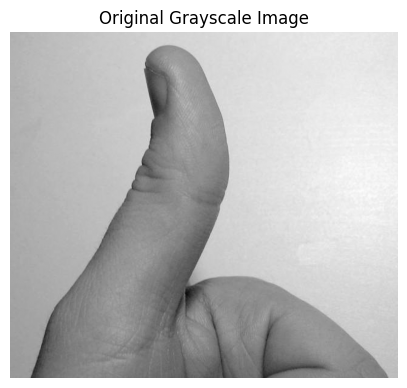

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request

# Unduh citra uji jika file lokal belum tersedia


img = cv2.imread('Thumbup.jpg', cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')
plt.show()

#### b. Mean Filter (Low-Pass Filter)

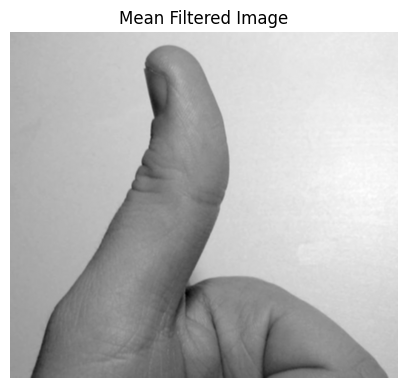

In [2]:
kernel_blur = np.ones((3, 3), np.float32) / 9.0
blurred = cv2.filter2D(img, -1, kernel_blur)

plt.figure(figsize=(5, 5))
plt.imshow(blurred, cmap='gray')
plt.title('Mean Filtered Image')
plt.axis('off')
plt.show()

#### c. Gaussian Filter

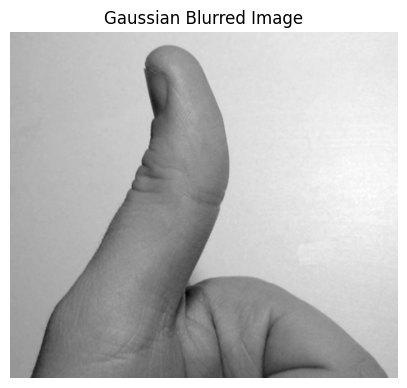

In [3]:
gaussian_blur = cv2.GaussianBlur(img, (3, 3), 0)

plt.figure(figsize=(5, 5))
plt.imshow(gaussian_blur, cmap='gray')
plt.title('Gaussian Blurred Image')
plt.axis('off')
plt.show()

#### d. Sharpening Filter

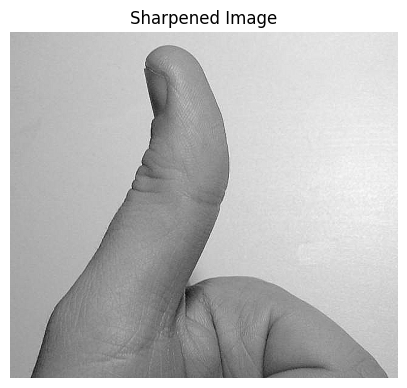

In [4]:
kernel_sharp = np.array([
    [0, -1,  0],
    [-1, 5, -1],
    [0, -1,  0]
])
sharpened = cv2.filter2D(img, -1, kernel_sharp)

plt.figure(figsize=(5, 5))
plt.imshow(sharpened, cmap='gray')
plt.title('Sharpened Image')
plt.axis('off')
plt.show()

#### e. Edge Detection Filter

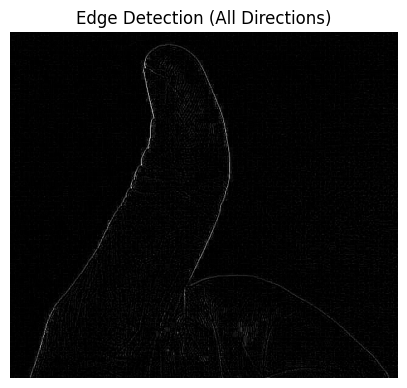

In [5]:
kernel_edge = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])
edges = cv2.filter2D(img, -1, kernel_edge)

plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap='gray')
plt.title('Edge Detection (All Directions)')
plt.axis('off')
plt.show()

#### f. Laplacian Filter

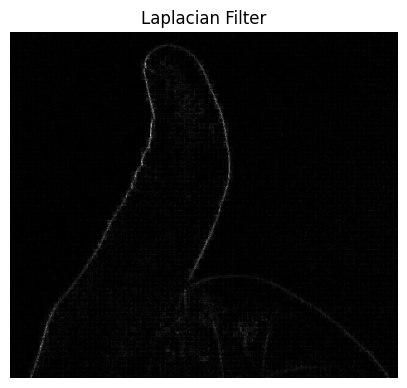

In [6]:
laplacian = cv2.Laplacian(img, cv2.CV_64F)

plt.figure(figsize=(5, 5))
plt.imshow(np.absolute(laplacian), cmap='gray')
plt.title('Laplacian Filter')
plt.axis('off')
plt.show()

#### g. Sobel Filter (X dan Y)

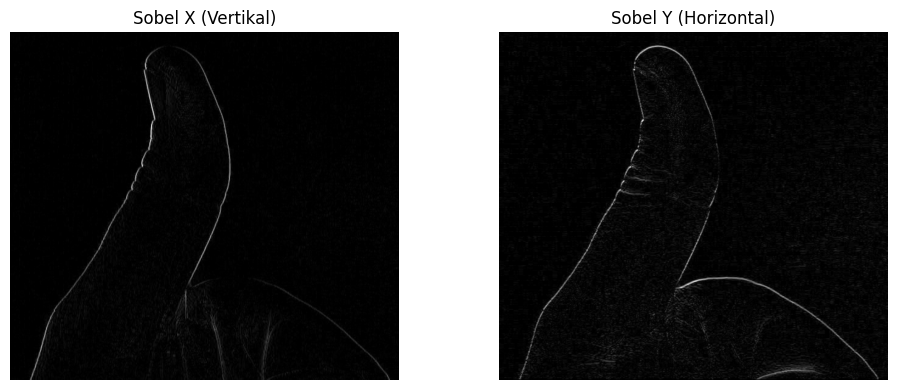

In [7]:
sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(np.absolute(sobelx), cmap='gray')
plt.title('Sobel X (Vertikal)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(np.absolute(sobely), cmap='gray')
plt.title('Sobel Y (Horizontal)')
plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Kesimpulan

- **Konvolusi** memanipulasi intensitas piksel berdasarkan relasi spasial tetangga terdekatnya.
- **Low-Pass Filter** (Mean, Gaussian) mereduksi derau dan variasi frekuensi tinggi pada citra.
- **High-Pass Filter** (Sharpening, Edge Detection, Laplacian, Sobel) menonjolkan transisi cepat intensitas piksel (tepi dan kontur objek).